# 01 - Training (SFT, two from-scratch DPO runs, LoRA persona)

Run this notebook first. Nothing has to be edited.

1. **Import:** Kaggle -> Create -> New Notebook -> File -> Import Notebook -> upload this file.
2. **Settings** (right panel, Session options): Accelerator **GPU T4 x2**, Internet **On**.
3. **Inputs:** none.
4. **Run:** **Save Version -> Save & Run All (Commit)**. It runs in the background; no open browser tab is needed.
5. **Afterwards:** send the status of the version (Complete or Failed) and its log; the last cell prints the
   summary tables. Then go on to notebook 02.

The notebook clones `https://github.com/zainahmadlums/genai-pa2.git` (branch `main`), installs the dependencies (PyTorch is left untouched),
checks for two GPUs, runs the offline tests, prepares the data, trains the four runs and writes plots and tables.
A step that fails raises a Python error and stops the run there; the error is the last thing in the log.

Expected time on T4 x2: SFT about 1.5 h, each DPO run 2 to 2.5 h, persona 10 to 20 min (6.5 to 8.5 h in total,
inside the 12 h session limit). To split the work across sessions, set `STAGES` in section 5 and attach the earlier
version's output through **Add Input**: finished stages found there are skipped.

Everything is written under `/kaggle/working/small-model-alignment/outputs/<run_name>/`.

## 1. Get the code

In [1]:
import os, shlex, shutil, subprocess, sys
from pathlib import Path

# ---- Settings: the defaults work as they are, nothing has to be edited ----------------------
REPO_URL = "https://github.com/zainahmadlums/genai-pa2.git"
REPO_BRANCH = "main"
CODE_DATASET_DIR = ""   # optional: use an uploaded copy of the code, e.g. "/kaggle/input/my-pa2-code/genaiPA2"
PREFER_ATTACHED_CODE = False   # True: take the code from an attached notebook output instead of GitHub
# ---------------------------------------------------------------------------------------------

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
REPO_DIR = WORK / "small-model-alignment"
CODE_MARKER = "scripts/judge_pairwise_kaggle.py"   # present only in a complete copy of the code


def run(*argv, **popen_options):
    """Run one command given as separate arguments (no shell, so spaces in paths are safe), output shown live.

    A non-zero exit status raises CalledProcessError, which stops "Run All" at this cell.
    """
    argv = [str(arg) for arg in argv]
    print("$", shlex.join(argv), flush=True)
    with subprocess.Popen(argv, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8",
                          errors="replace", **popen_options) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
    if process.returncode != 0:
        raise subprocess.CalledProcessError(process.returncode, argv)


def py(*argv, **popen_options):
    """Run a script or module with this notebook's Python interpreter."""
    run(sys.executable, *argv, **popen_options)


def find_code_in_inputs():
    """A copy of the code inside an attached input (an uploaded dataset or an earlier notebook's output)."""
    matches = sorted(INPUT.glob("**/" + CODE_MARKER))
    return matches[0].parents[1] if matches else None


if (REPO_DIR / CODE_MARKER).exists():
    print("using the code already at", REPO_DIR, "as it is (an existing copy is never updated)")
elif REPO_DIR.exists():
    raise RuntimeError(f"{REPO_DIR} exists but is not a complete copy of the code. Delete it (or restart the "
                       "session) and run this cell again.")
else:
    if CODE_DATASET_DIR:
        source = Path(CODE_DATASET_DIR)
        if not (source / CODE_MARKER).exists():
            raise FileNotFoundError(f"CODE_DATASET_DIR={CODE_DATASET_DIR!r} does not contain {CODE_MARKER}")
    else:
        source = find_code_in_inputs() if PREFER_ATTACHED_CODE else None
    if source is not None:
        shutil.copytree(source, REPO_DIR, ignore=shutil.ignore_patterns("outputs", ".git", ".venv", "__pycache__"))
        print("copied the code from", source)
    else:
        if PREFER_ATTACHED_CODE:
            print("no copy of the code in the attached inputs; cloning it instead (needs Internet On)")
        run("git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, REPO_DIR)

os.chdir(REPO_DIR)
os.environ["PYTHONUNBUFFERED"] = "1"   # training / generation logs appear line by line
sys.path.insert(0, str(REPO_DIR))
print("working directory:", os.getcwd())

$ git clone --depth 1 --branch main https://github.com/zainahmadlums/genai-pa2.git /kaggle/working/small-model-alignment
Cloning into '/kaggle/working/small-model-alignment'...
working directory: /kaggle/working/small-model-alignment


## 2. Install dependencies (PyTorch is left untouched)

In [2]:
# Keeps Kaggle's CUDA build of PyTorch: torch is never installed or pinned here.
py("-m", "pip", "uninstall", "-y", "-q", "torchao")
py("-m", "pip", "install", "-q", "transformers>=4.56.2,<5", "datasets>=4.7,<5", "huggingface_hub",
   "accelerate>=1.4.0", "tqdm", "pyyaml", "sentencepiece", "safetensors", "matplotlib", "peft>=0.17.0",
   "trl==1.14.1", "pytest")
py("-m", "pip", "install", "-q", "-e", ".", "--no-deps")

$ /usr/bin/python3 -m pip uninstall -y -q torchao
$ /usr/bin/python3 -m pip install -q 'transformers>=4.56.2,<5' 'datasets>=4.7,<5' huggingface_hub 'accelerate>=1.4.0' tqdm pyyaml sentencepiece safetensors matplotlib 'peft>=0.17.0' trl==1.14.1 pytest
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 512.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 925.5/925.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 94.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you 

## 3. Check the environment: two T4 GPUs and package versions

In [3]:
py("scripts/check_env.py", "--require_gpus", "2")

$ /usr/bin/python3 scripts/check_env.py --require_gpus 2
python       3.13.15 (Linux-6.18.48+-x86_64-with-glibc2.39)
torch        2.11.0+cu128
transformers 4.57.6
datasets     4.8.5
accelerate   1.14.0
peft         0.20.0
trl          1.14.1
huggingface_hub 0.36.2
kaggle_benchmarks not available (ModuleNotFoundError)
cuda         available=True build=12.8 gpus=2
  cuda:0     Tesla T4 14.6 GiB
  cuda:1     Tesla T4 14.6 GiB
Mon Oct 12 17:10:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |             

## 4. Offline tests (public adapter contract and training math; no downloads)

In [4]:
py("-m", "pytest", "-q", "tests", env={**os.environ, "PYTHONPATH": str(REPO_DIR)})

$ /usr/bin/python3 -m pytest -q tests
........................................................................ [ 31%]
........................................................................ [ 63%]
........................................................................ [ 95%]
...........                                                              [100%]
227 passed in 75.31s (0:01:15)


## 5. Choose stages and look for finished runs

`finished(run)` finds a completed run in this session or in any attached input, so a later session never repeats
a stage that already finished. `checkpoint(run)` returns its weights and raises if the run is not complete.

In [5]:
STAGES = ["sft", "dpo_hh", "dpo_ultrafeedback", "persona_lora"]   # remove entries to run only part of the pipeline
RUN_SMOKE = False   # optional: True adds a 4-step smoke run before each full run (not needed for Save & Run All)

In [6]:
RUNS = {"sft": "best", "dpo_hh": "best", "dpo_ultrafeedback": "best", "persona_lora": "adapter"}   # run -> checkpoint


def finished(run_name):
    """Directory of a finished run: outputs/<run_name> in this session, else inside any attached input."""
    local = Path("outputs") / run_name
    if (local / "TRAINING_COMPLETE.json").exists():
        return local
    matches = sorted(INPUT.glob(f"**/outputs/{run_name}/TRAINING_COMPLETE.json"))
    return matches[-1].parent if matches else None


def checkpoint(run_name):
    """Checkpoint directory of a finished run. Raises when the run did not finish or its weights are missing."""
    run_dir = finished(run_name)
    if run_dir is None:
        raise FileNotFoundError(f"run '{run_name}' is not finished: no outputs/{run_name}/TRAINING_COMPLETE.json in "
                                "this session or in an attached input (Add Input -> Notebooks -> the saved version "
                                "of notebook 01 that completed it)")
    path = run_dir / RUNS[run_name]
    if not path.is_dir():
        raise FileNotFoundError(f"run '{run_name}' is marked finished but its checkpoint {path} is missing")
    return path


for name in RUNS:
    print(f"{name:18s} {finished(name) or 'not finished yet'}")

unknown = [name for name in STAGES if name not in RUNS]
if unknown:
    raise ValueError(f"unknown entries in STAGES: {unknown}; choose from {list(RUNS)}")


def stage_needed(name):
    return name in STAGES and finished(name) is None

sft                not finished yet
dpo_hh             not finished yet
dpo_ultrafeedback  not finished yet
persona_lora       not finished yet


## 6. Prepare data

Builds the single-turn files in `outputs/data/` (30k/1k SFT, 15k/1k HH, 15k/1k UltraFeedback) from pinned dataset
revisions and writes a `*_provenance.json` next to each. Prompts of the fixed evaluation sets are excluded.
Existing files are kept.

In [7]:
py("scripts/make_alpaca_eval_subset.py", "--verify")
for stage, task in (("sft", "sft"), ("dpo_hh", "hh"), ("dpo_ultrafeedback", "ultrafeedback")):
    if stage_needed(stage):
        py("scripts/prepare_data.py", "--task", task)
for path in sorted(Path("outputs/data").glob("*")):
    print(f"{path.stat().st_size:>13,d}  {path}")

$ /usr/bin/python3 scripts/make_alpaca_eval_subset.py --verify
OK: eval_sets/alpaca_eval_300_seed42.json matches the regenerated subset (300 prompts)
$ /usr/bin/python3 scripts/prepare_data.py --task sft
[prepare] excluding 525 fixed evaluation prompts from 3 files

Generating train_sft split: 100%|██████████| 207865/207865 [00:04<00:00, 50829.94 examples/s]

Generating test_sft split: 100%|██████████| 23110/23110 [00:00<00:00, 57469.44 examples/s]

Generating train_gen split: 100%|██████████| 256032/256032 [00:03<00:00, 69113.43 examples/s]

Generating test_gen split: 100%|██████████| 28304/28304 [00:00<00:00, 66542.93 examples/s]
[prepare:sft] 207843 single-turn candidates from HuggingFaceH4/ultrachat_200k
[prepare:sft] wrote 30000 train / 1000 val rows to outputs/data (dropped before quota: {'response_does_not_fit': 16603, 'prompt_too_long': 11779, 'response_too_short': 3})
$ /usr/bin/python3 scripts/prepare_data.py --task hh
[prepare] excluding 525 fixed evaluation prompts from 3 f

## 7. SFT

The resume state goes to `/kaggle/temp`, which does not count against the 20 GB output quota and survives a kernel
restart in the same session.

In [8]:
if stage_needed("sft"):
    if RUN_SMOKE:
        py("scripts/train_sft.py", "--config", "configs/sft.yaml", "--smoke")
    py("scripts/train_sft.py", "--config", "configs/sft.yaml", "--resume",
       "--override", "resume_every_steps=250", "resume_dir=/kaggle/temp/resume/sft")
    py("scripts/package_outputs.py", "--source", "outputs/sft", "outputs/data",
       "--zip_path", WORK / "sft_run_outputs.zip")
    print("SFT best checkpoint:", checkpoint("sft"))   # raises if the run did not finish

$ /usr/bin/python3 scripts/train_sft.py --config configs/sft.yaml --resume --override resume_every_steps=250 resume_dir=/kaggle/temp/resume/sft
`torch_dtype` is deprecated! Use `dtype` instead!
[sft] model=Qwen/Qwen2.5-0.5B device=cuda:0 train=30000 val=1000
[sft] rows=30000 batch=2 accum=16 optimizer_steps=938 warmup=29 precision=fp16 device=cuda:0
[sft] eval step 0/938 val_loss=1.3538 val_perplexity=3.8723 val_nll_per_example=307.6508
[sft] step 10/938 loss=1.3471 lr=6.90e-06 grad_norm=4.8667 skipped_steps=0 elapsed=81s
[sft] step 20/938 loss=1.3052 lr=1.38e-05 grad_norm=4.7850 skipped_steps=0 elapsed=124s
[sft] step 30/938 loss=1.3604 lr=2.00e-05 grad_norm=4.7051 skipped_steps=0 elapsed=167s
[sft] step 40/938 loss=1.3538 lr=2.00e-05 grad_norm=4.6497 skipped_steps=0 elapsed=210s
[sft] step 50/938 loss=1.3594 lr=2.00e-05 grad_norm=4.6986 skipped_steps=0 elapsed=254s
[sft] step 60/938 loss=1.3416 lr=1.99e-05 grad_norm=4.6999 skipped_steps=0 elapsed=297s
[sft] step 70/938 loss=1.3971 lr

## 8. DPO on HH-RLHF

Policy on `cuda:0`, frozen reference on `cuda:1`, both loaded from the SFT best checkpoint.
The step-0 validation must show reward accuracy 0.0 and margin 0.0: policy and reference are identical, so all
rewards tie and the strict comparison counts none as correct.

In [9]:
if stage_needed("dpo_hh"):
    SFT_BEST = checkpoint("sft")   # raises unless SFT finished above or in an attached input
    if RUN_SMOKE:
        py("scripts/train_dpo.py", "--config", "configs/dpo_hh.yaml", "--smoke",
           "--override", f"sft_checkpoint={SFT_BEST}")
    py("scripts/train_dpo.py", "--config", "configs/dpo_hh.yaml", "--resume",
       "--override", f"sft_checkpoint={SFT_BEST}", "resume_every_steps=100", "resume_dir=/kaggle/temp/resume/dpo_hh")
    py("scripts/package_outputs.py", "--source", "outputs/dpo_hh", "--zip_path", WORK / "dpo_hh_run_outputs.zip")
    print("DPO (HH) best checkpoint:", checkpoint("dpo_hh"))

$ /usr/bin/python3 scripts/train_dpo.py --config configs/dpo_hh.yaml --resume --override sft_checkpoint=outputs/sft/best resume_every_steps=100 resume_dir=/kaggle/temp/resume/dpo_hh
The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
[dpo] sft_checkpoint=outputs/sft/best policy=cuda:0 reference=cuda:1 (fp32) train=15000 val=1000 template=alpaca
[dpo_hh] rows=15000 batch=1 accum=32 optimizer_steps=469 warmup=0 precision=fp16 device=cuda:0
[dpo_hh] eval step 0/469 val_loss=0.6931 val_reward_accuracy=0.0000 val_reward_margin=0.0000 val_tie_fraction=1.0000 val_policy_chosen_logp=-143.2173 val_policy_rejected_logp=-150.5718 val_reference_chosen_logp=-143.2173 val_

## 9. DPO on UltraFeedback (same code, same SFT checkpoint, different data)

In [10]:
if stage_needed("dpo_ultrafeedback"):
    SFT_BEST = checkpoint("sft")
    py("scripts/train_dpo.py", "--config", "configs/dpo_ultrafeedback.yaml", "--resume",
       "--override", f"sft_checkpoint={SFT_BEST}", "resume_every_steps=100",
       "resume_dir=/kaggle/temp/resume/dpo_ultrafeedback")
    py("scripts/package_outputs.py", "--source", "outputs/dpo_ultrafeedback",
       "--zip_path", WORK / "dpo_ultrafeedback_run_outputs.zip")
    print("DPO (UltraFeedback) best checkpoint:", checkpoint("dpo_ultrafeedback"))

$ /usr/bin/python3 scripts/train_dpo.py --config configs/dpo_ultrafeedback.yaml --resume --override sft_checkpoint=outputs/sft/best resume_every_steps=100 resume_dir=/kaggle/temp/resume/dpo_ultrafeedback
The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
[dpo] sft_checkpoint=outputs/sft/best policy=cuda:0 reference=cuda:1 (fp32) train=15000 val=1000 template=alpaca
[dpo_ultrafeedback] rows=15000 batch=1 accum=32 optimizer_steps=469 warmup=0 precision=fp16 device=cuda:0
[dpo_ultrafeedback] eval step 0/469 val_loss=0.6931 val_reward_accuracy=0.0000 val_reward_margin=0.0000 val_tie_fraction=1.0000 val_policy_chosen_logp=-279.5366 val_policy_rejected_logp=-218.8

## 10. Persona: TRL DPOTrainer + LoRA on SmolLM2-360M-Instruct

In [11]:
if stage_needed("persona_lora"):
    if RUN_SMOKE:
        py("scripts/train_persona_lora.py", "--config", "configs/persona_lora.yaml", "--smoke")
    py("scripts/train_persona_lora.py", "--config", "configs/persona_lora.yaml")
    py("scripts/package_outputs.py", "--source", "outputs/persona_lora",
       "--zip_path", WORK / "persona_lora_run_outputs.zip", "--include_weights")
    print("persona adapter:", checkpoint("persona_lora"))

$ /usr/bin/python3 scripts/train_persona_lora.py --config configs/persona_lora.yaml
`torch_dtype` is deprecated! Use `dtype` instead!

Tokenizing train dataset: 100%|██████████| 200/200 [00:00<00:00, 681.54 examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/200 [00:00<?, ? examples/s]
Dropping fully truncated examples from train dataset: 100%|██████████| 200/200 [00:00<00:00, 9113.40 examples/s]

Tokenizing eval dataset: 100%|██████████| 20/20 [00:00<00:00, 600.48 examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/20 [00:00<?, ? examples/s]
Dropping fully truncated examples from eval dataset: 100%|██████████| 20/20 [00:00<00:00, 4211.15 examples/s]
[persona] trl=1.14.1 train=200 val=20 trainable=8,683,520 of 370,504,640 parameters (2.34%)

100%|██████████| 3/3 [00:00<00:00,  5.73it/s]

  7%|▋         | 5/75 [00:04<00:55,  1.27it/s]
                                              
{'loss': 0.6893, 'grad_norm': 1.57764029

## 11. Training plots and summary tables

Every stage in `STAGES` must be finished with its checkpoint in place by now, otherwise this cell raises. The plots
and tables cover every finished run, including runs found in attached inputs.

In [12]:
for name in STAGES:
    print(f"{name:18s} {checkpoint(name)}")
RUN_DIRS = [finished(name) for name in RUNS if finished(name) is not None]
py("scripts/plot_metrics.py", "--run_dir", *RUN_DIRS, "--out_dir", "outputs/plots")
py("scripts/summarize_results.py", "--runs", *RUN_DIRS, "--out_dir", "outputs/report")
py("scripts/package_outputs.py", "--source", "outputs/plots", "outputs/report",
   "--zip_path", WORK / "training_plots_and_report.zip")

sft                outputs/sft/best
dpo_hh             outputs/dpo_hh/best
dpo_ultrafeedback  outputs/dpo_ultrafeedback/best
persona_lora       outputs/persona_lora/adapter
$ /usr/bin/python3 scripts/plot_metrics.py --run_dir outputs/sft outputs/dpo_hh outputs/dpo_ultrafeedback outputs/persona_lora --out_dir outputs/plots
[plot] wrote outputs/plots/sft_curves.png
[plot] wrote outputs/plots/dpo_hh_curves.png
[plot] wrote outputs/plots/dpo_ultrafeedback_curves.png
[plot] wrote outputs/plots/persona_lora_curves.png
$ /usr/bin/python3 scripts/summarize_results.py --runs outputs/sft outputs/dpo_hh outputs/dpo_ultrafeedback outputs/persona_lora --out_dir outputs/report
[summarize] 4 runs, 0 judged comparisons, 0 generation files -> outputs/report
$ /usr/bin/python3 scripts/package_outputs.py --source outputs/plots outputs/report --zip_path /kaggle/working/training_plots_and_report.zip
[package] /kaggle/working/training_plots_and_report.zip: 10 files, 0.8 MB before compression, 0 weight files

outputs/plots/dpo_hh_curves.png


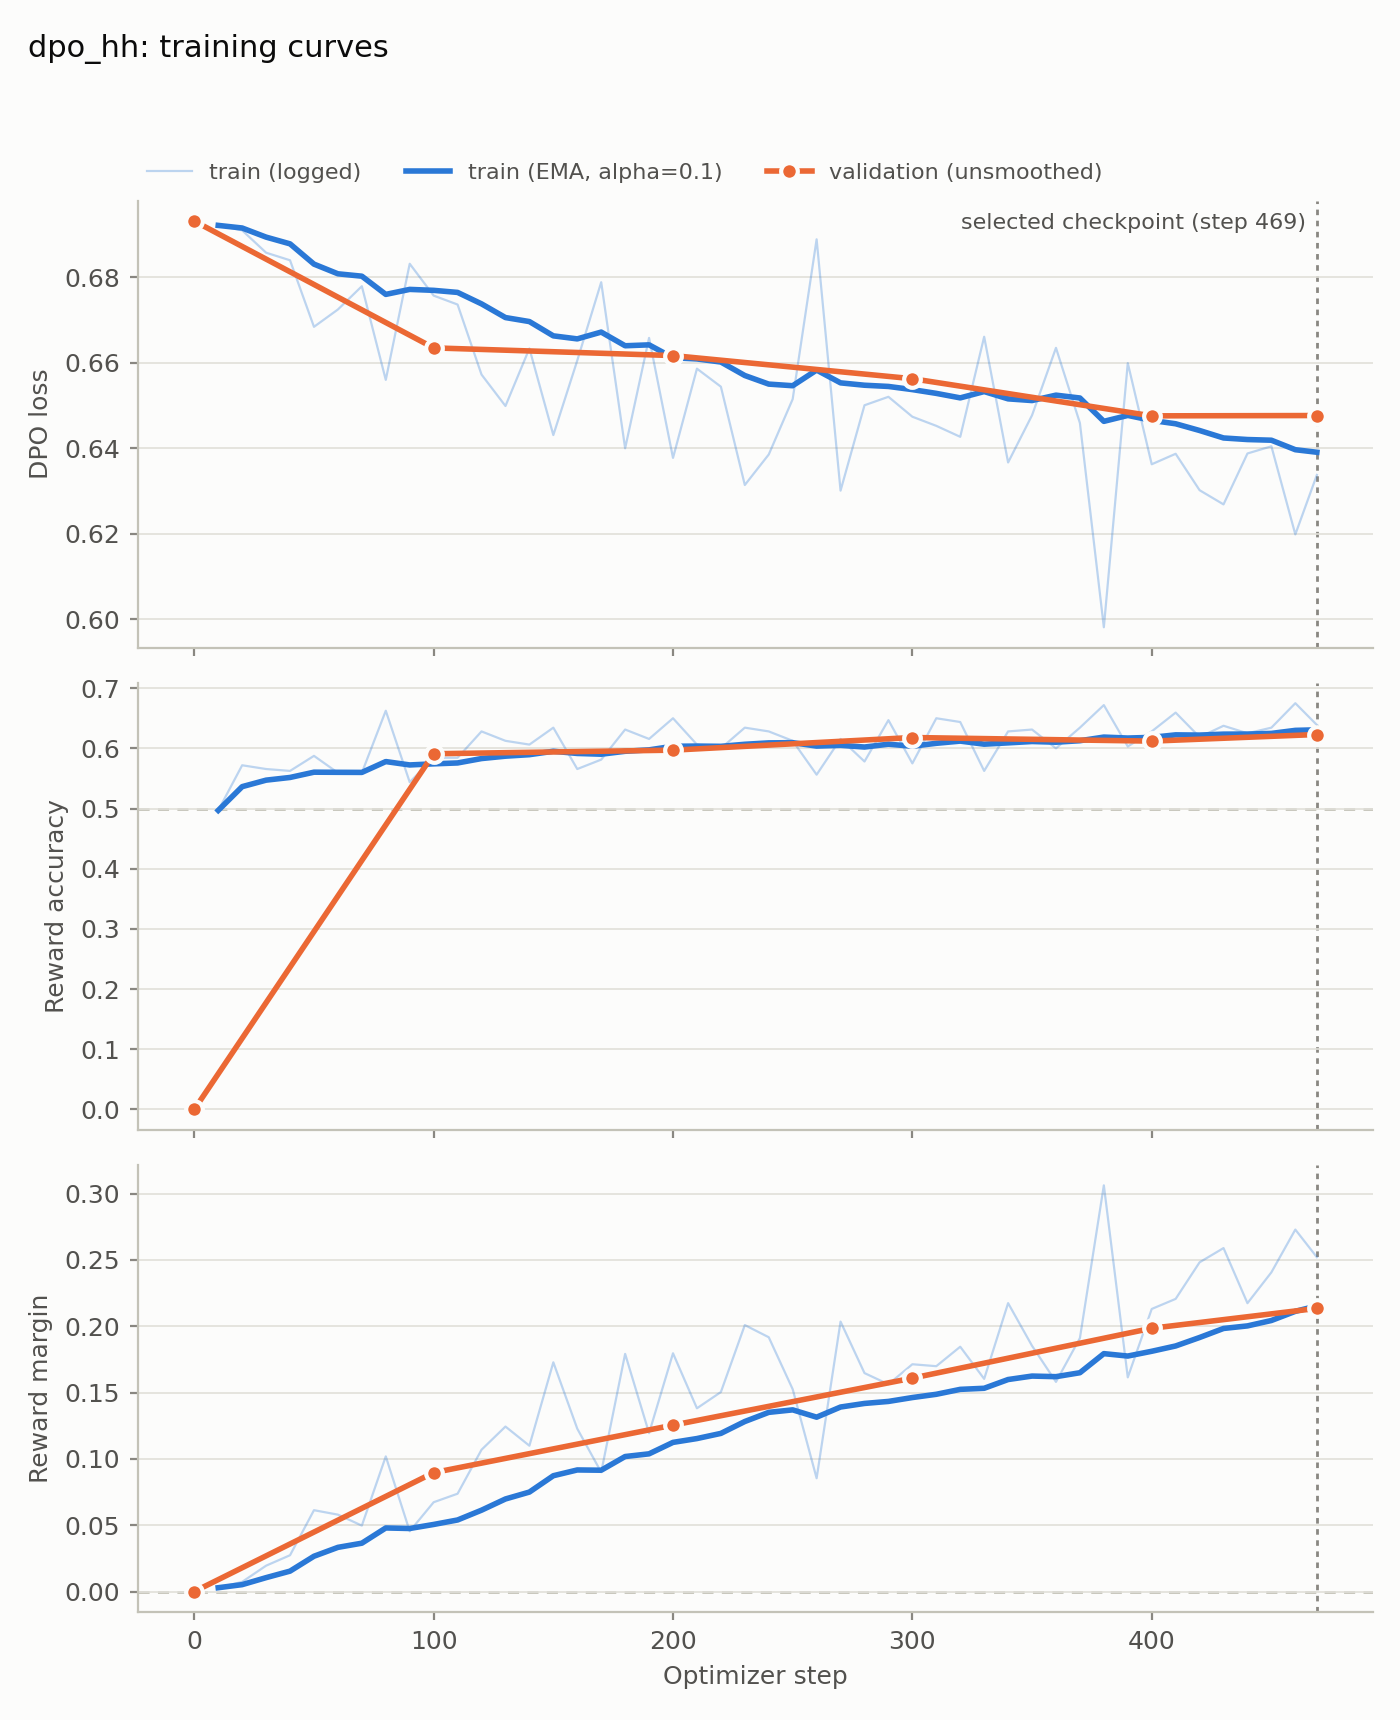

outputs/plots/dpo_ultrafeedback_curves.png


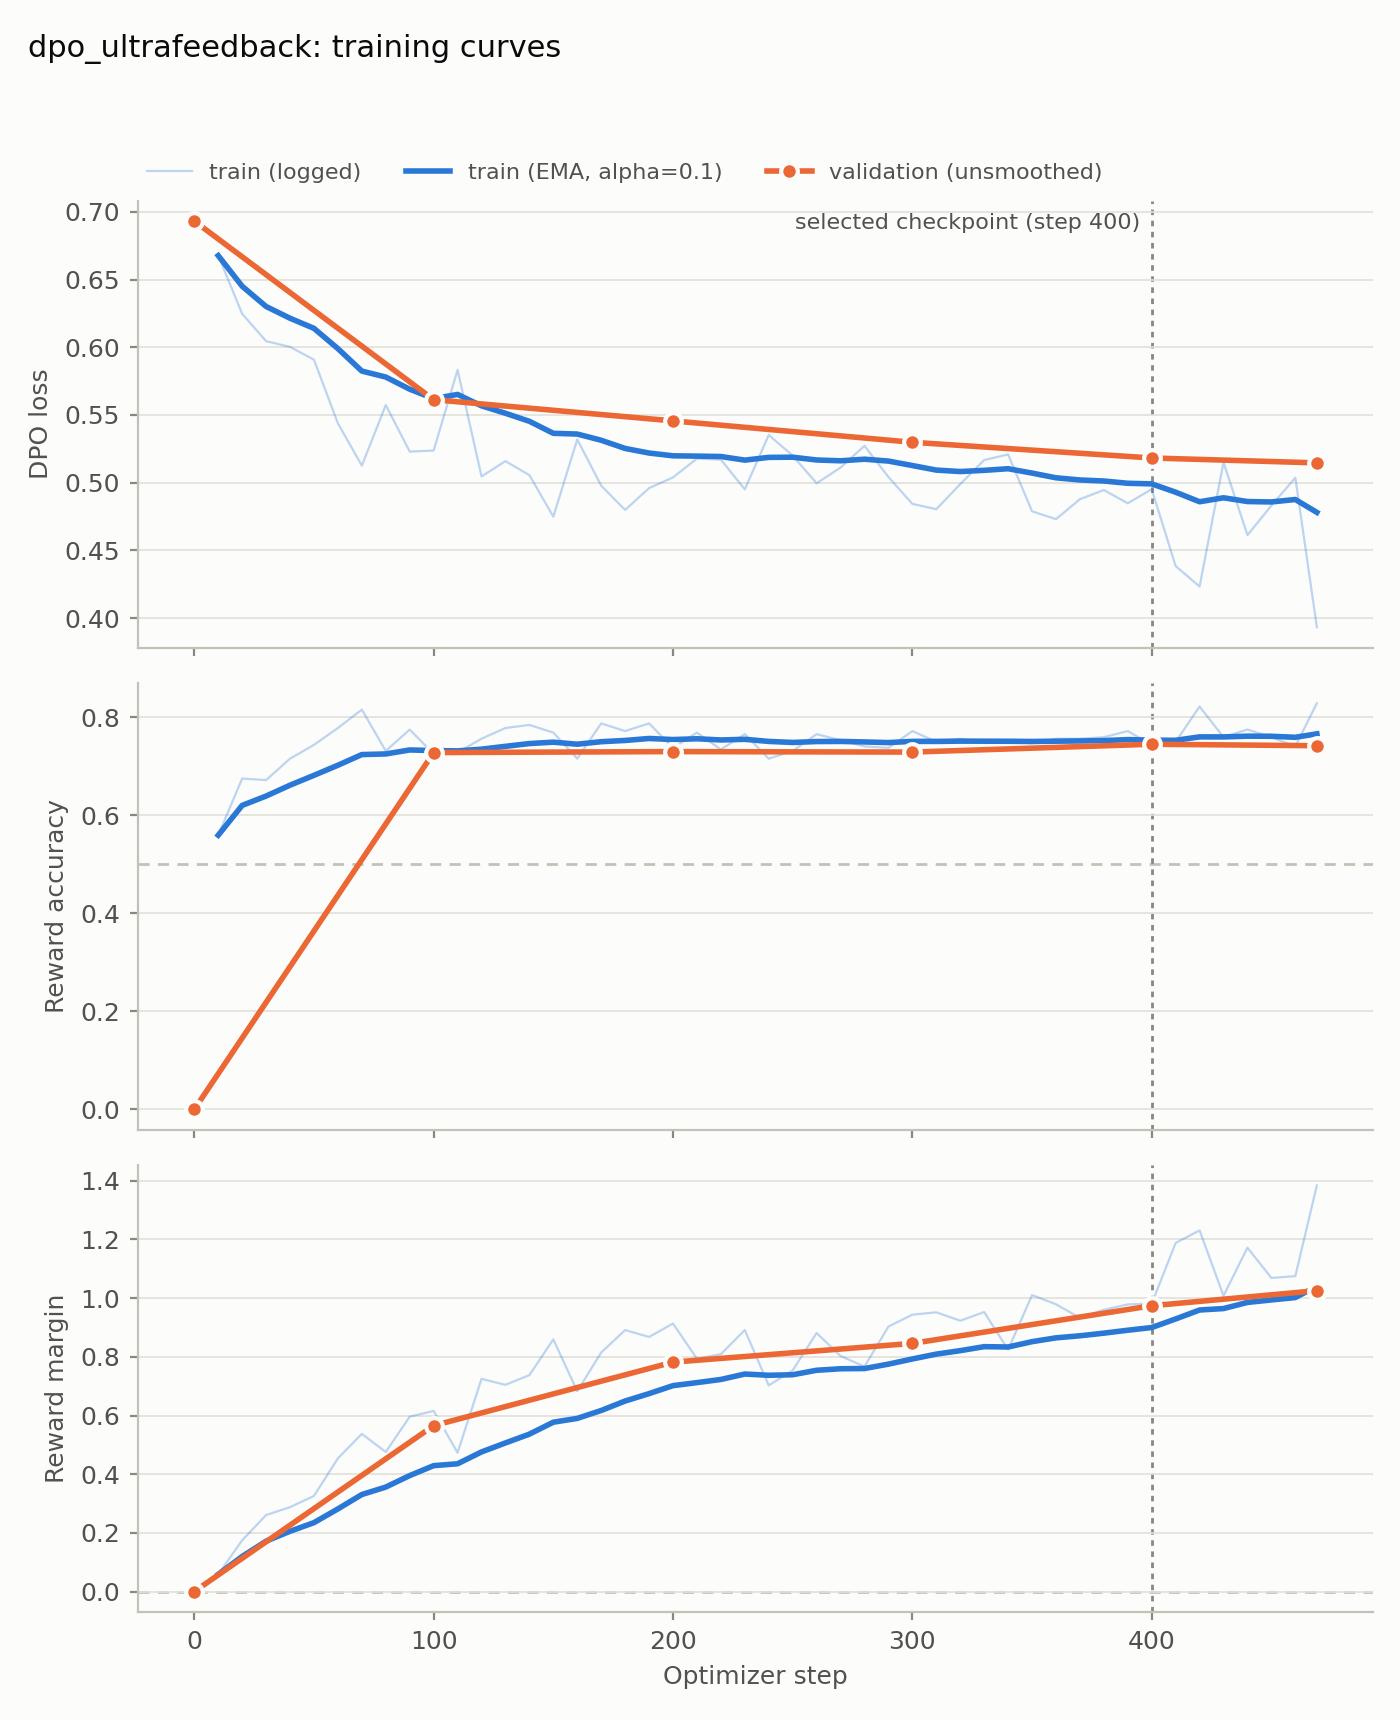

outputs/plots/persona_lora_curves.png


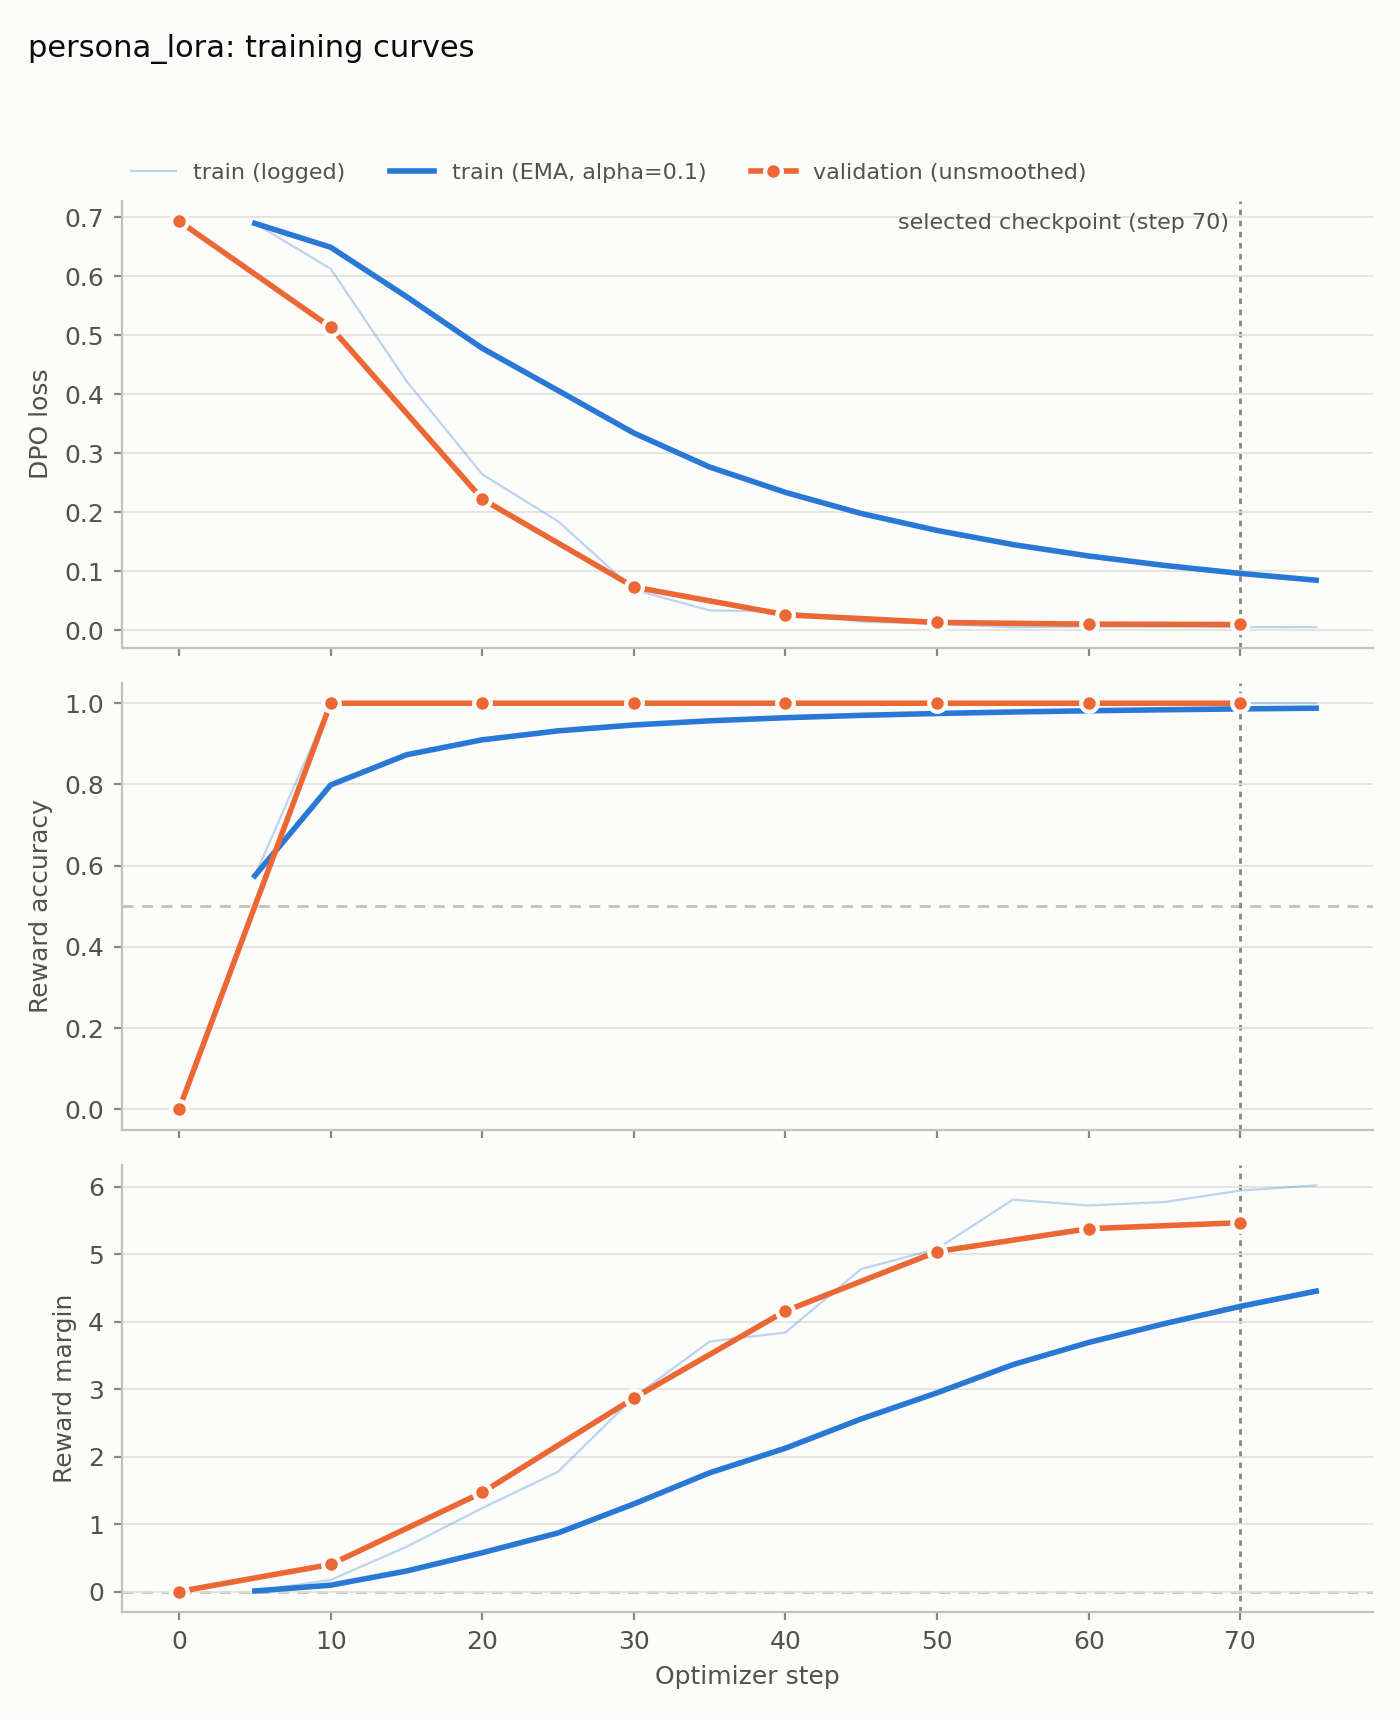

outputs/plots/sft_curves.png


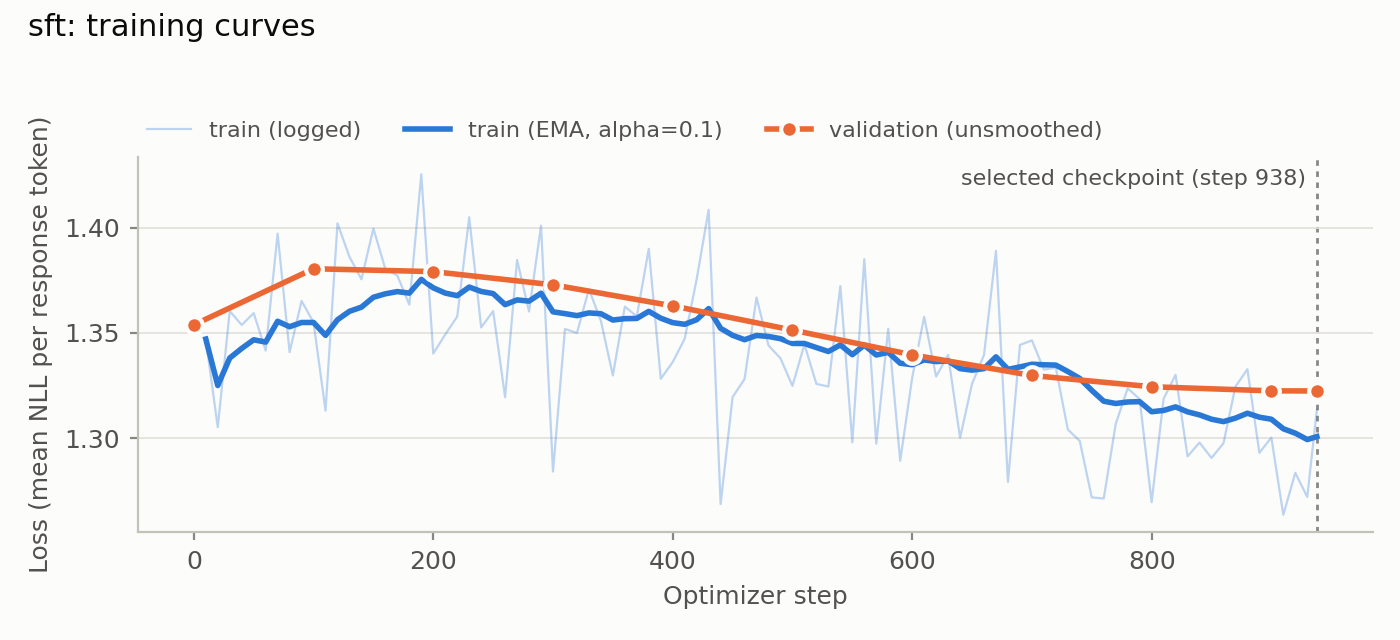

In [13]:
from IPython.display import Image, display
for path in sorted(Path("outputs/plots").glob("*_curves.png")):
    print(path)
    display(Image(filename=str(path)))

## 12. Disk use and summary

The three Qwen runs hold about 12 GB of checkpoints (best + final, fp32); the output limit is 20 GB.
The zip files contain metrics, configs, logs and plots only (no weights), so they are small and easy to download.

With **Save & Run All (Commit)** the outputs are attached to the saved version. Open notebook 02 next and attach
this notebook with **Add Input -> Notebooks**.

**Restarting:** run all cells again. A finished stage is skipped. An interrupted stage continues from
`/kaggle/temp/resume/<run>` while the session is alive and restarts from its beginning in a new session.

In [14]:
def size_gb(path):
    files = [path] if path.is_file() else [item for item in path.rglob("*") if item.is_file()]
    return sum(item.stat().st_size for item in files) / 1e9

for path in sorted(Path("outputs").glob("*")) + sorted(WORK.glob("*.zip")):
    print(f"{size_gb(path):8.2f} GB  {path}")
usage = shutil.disk_usage(WORK)
print(f"{usage.free / 1e9:.1f} GB free of {usage.total / 1e9:.1f} GB at {WORK}")

print(Path("outputs/report/report_tables.md").read_text(encoding="utf-8"))
print("NOTEBOOK 01 FINISHED. Stages complete:", ", ".join(STAGES))

    0.09 GB  outputs/data
    3.98 GB  outputs/dpo_hh
    3.98 GB  outputs/dpo_ultrafeedback
    0.26 GB  outputs/persona_lora
    0.00 GB  outputs/plots
    0.00 GB  outputs/report
    3.98 GB  outputs/sft
    0.01 GB  /kaggle/working/dpo_hh_run_outputs.zip
    0.01 GB  /kaggle/working/dpo_ultrafeedback_run_outputs.zip
    0.23 GB  /kaggle/working/persona_lora_run_outputs.zip
    0.04 GB  /kaggle/working/sft_run_outputs.zip
    0.00 GB  /kaggle/working/training_plots_and_report.zip
8.3 GB free of 21.0 GB at /kaggle/working
# Report tables (generated by scripts/summarize_results.py)

Every number below was read from a file on disk. `n/a` means the file was not found.

## Experimental configuration

| Run | Trainable parameters | Optimizer | Peak LR | Schedule | Warmup | Weight decay | Clip | Batch x accum = effective | Precision | Max len | Epochs | Steps | Seed | Beta | Reference checkpoint | Prompt format |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| sft |